# IT9002 Lab 6.1: Training a Neural Classifier on Movie Reviews

**Unit 06: Neural Sequence Models**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Establish a logistic regression baseline on the TF-IDF values of movie reviews.
- Use Keras to build and train a neural network on the same values.
- Interpret a model summary, the loss curves, and the effect of early stopping.
- Evaluate the network against the baseline on the test reviews.
- Use a saved network to predict the sentiment of new reviews.

## Data

- **IMDB Large Movie Review Dataset** (Maas et al., 2011), 10,000 reviews of the training split, 5,000 positive and 5,000 negative, with a saved split into 7,000 training, 1,500 validation, and 1,500 test reviews, https://ai.stanford.edu/~amaas/data/sentiment/, released by the authors for research use.

- The course file `imdb_sample.csv` (on Moodle).

The file `imdb_sample.csv` can be downloaded from Moodle. Download it to your computer, then run the cell below. If the file is already available in the runtime, the cell loads it directly; otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

DATA = "imdb_sample.csv"
path = next((p for p in (Path(DATA), Path("data") / DATA) if p.exists()), None)
if path is None:
    from google.colab import files
    files.upload()
    path = Path(DATA)

reviews = pd.read_csv(path)
print(reviews.shape)
reviews.head()

(10000, 4)


,review_id,label,split,text
0,0,negative,train,I rented I AM CURIOUS-YELLOW from my video sto...
1,3,negative,train,This film was probably inspired by Godard's Ma...
2,8,negative,validation,"Who are these ""They""- the actors? the filmmake..."
3,10,negative,validation,It was great to see some of my favorite stars ...
4,12,negative,test,Never cast models and Playboy bunnies in your ...


## Setup

Imports the libraries and tools required for the lab and displays the installed versions of **TensorFlow**, **Keras**, and **scikit-learn**, all preinstalled in Google Colab. The lab uses Keras 3.

In [2]:
import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import tensorflow as tf
from keras import layers
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

tf.get_logger().setLevel("ERROR")  # hides TensorFlow warnings about the runtime
pd.set_option("display.max_colwidth", 100)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| scikit-learn", sklearn.__version__)

TensorFlow 2.21.0 | Keras 3.15.1 | scikit-learn 1.9.1


## 1. Movie Reviews and the Saved Split

`split_reviews()` returns the texts and the labels of the three sets of the `split` column, with 0 for negative and 1 for positive. The reviews are counted by set and label:

In [3]:
LABELS = ["negative", "positive"]

def split_reviews(reviews):
    parts = {}
    for name in ("train", "validation", "test"):
        part = reviews[reviews.split == name]
        labels = (part.label == "positive").astype(int).to_numpy()
        parts[name] = (part.text.to_numpy(), labels)
    return parts

parts = split_reviews(reviews)
texts_train, y_train = parts["train"]
texts_val, y_val = parts["validation"]
texts_test, y_test = parts["test"]
reviews.groupby(["split", "label"]).size().unstack()

label,negative,positive
split,,
test,750,750
train,3500,3500
validation,750,750


## 2. TF-IDF Values of the Reviews

`TfidfVectorizer` is fitted on the training reviews only and keeps the 10,000 most frequent terms.

`transform()` returns a table that stores only the non-zero values. `tfidf_values()` converts texts into a full **NumPy** array of TF-IDF values (`float32`), the input format of a Keras network:

- `vectorizer`: a fitted `TfidfVectorizer`.

- `texts`: the reviews to convert, for example `texts_val`.

The shapes of the three arrays and the number of non-zero values in the first training review are displayed:

In [4]:
VOCAB_SIZE = 10_000

def tfidf_values(vectorizer, texts):
    return vectorizer.transform(texts).astype(np.float32).toarray()

tfidf = TfidfVectorizer(max_features=VOCAB_SIZE)
tfidf.fit(texts_train)
X_train = tfidf_values(tfidf, texts_train)
X_val = tfidf_values(tfidf, texts_val)
X_test = tfidf_values(tfidf, texts_test)
print(X_train.shape, X_val.shape, X_test.shape)
print("non-zero values in the first training review:", int((X_train[0] > 0).sum()))

(7000, 10000) (1500, 10000) (1500, 10000)
non-zero values in the first training review: 164


## 3. A Logistic Regression Baseline

`scores()` returns the accuracy and the macro F1 of predicted labels against the actual labels.

The baseline, a logistic regression on the same values, is trained and scored on the validation reviews:

In [5]:
def scores(y_true, y_pred):
    return {"accuracy": round(accuracy_score(y_true, y_pred), 3),
            "macro F1": round(f1_score(y_true, y_pred, average="macro"), 3)}

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train, y_train)
print("validation:", scores(y_val, baseline.predict(X_val)))

validation: {'accuracy': 0.867, 'macro F1': 0.867}


## 4. Building the Network

`build_tfidf_network()` constructs a network with one hidden ReLU layer and a softmax output layer of 2 neurons. It compiles it with the Adam optimizer and `sparse_categorical_crossentropy`, the cross-entropy loss for labels stored as numbers:

- `vocab_size`: the number of input values, one for each vocabulary term, for example `10_000`.

- `hidden_units`: the number of hidden neurons, for example `16`.

- `seed`: fixes the random starting weights, so the same network is constructed on every run, for example `42`.

The summary of the network is displayed:

In [6]:
HIDDEN_UNITS = 16
SEED = 42

def build_tfidf_network(vocab_size=VOCAB_SIZE, hidden_units=HIDDEN_UNITS, seed=SEED):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input(shape=(vocab_size,)),
        layers.Dense(hidden_units, activation="relu"),
        layers.Dense(2, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

network = build_tfidf_network()
network.summary(line_length=65)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ Layer (type)               ┃ Output Shape        ┃    Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━┩
│ dense (Dense)              │ (None, 16)          │    160,016 │
├────────────────────────────┼─────────────────────┼────────────┤
│ dense_1 (Dense)            │ (None, 2)           │         34 │
└────────────────────────────┴─────────────────────┴────────────┘

 Total params: 160,050 (625.20 KB)

 Trainable params: 160,050 (625.20 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Training the Network and Reading the Loss Curves

`train()` trains a network and returns the training and validation loss and accuracy of every epoch, as lists under the keys `loss`, `accuracy`, `val_loss`, and `val_accuracy`:

- `model`: the network to train.

- `X_train`, `y_train`, `X_val`, `y_val`: the input values and labels of the training and validation reviews.

- `epochs`: the largest number of epochs, for example `20`.

- `patience`: the number of epochs without a lower validation loss before training stops and the best weights are restored, for example `2`. The default `None` trains for every epoch.

`plot_loss_curves()` plots the training and validation losses, one panel below another for each network, and circles the lowest validation loss:

- `histories`: a dictionary from a network's name to the values returned by `train()`.

The network is trained for 20 epochs without early stopping:

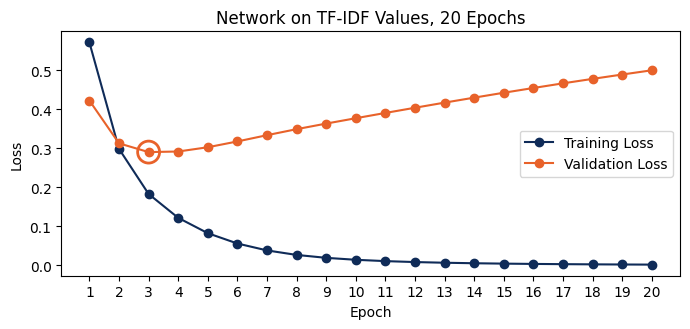

In [7]:
EPOCHS = 20
BATCH_SIZE = 32

def train(model, X_train, y_train, X_val, y_val, epochs=EPOCHS, patience=None):
    callbacks = []
    if patience is not None:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                       restore_best_weights=True))
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                        batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)
    return history.history

def plot_loss_curves(histories):
    fig, axes = plt.subplots(len(histories), 1, figsize=(7, 3.4 * len(histories)), squeeze=False)
    for ax, (name, history) in zip(axes[:, 0], histories.items()):
        epochs = range(1, len(history["loss"]) + 1)
        best = int(np.argmin(history["val_loss"]))
        ax.plot(epochs, history["loss"], color="#0F2B58", marker="o", label="Training Loss")
        ax.plot(epochs, history["val_loss"], color="#E8622A", marker="o", label="Validation Loss")
        ax.scatter(best + 1, history["val_loss"][best], s=250, facecolors="none", edgecolors="#E8622A",
                   linewidths=2)
        ax.set_title(name)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_xticks(list(epochs))
        ax.legend(loc="best")
    plt.tight_layout()
    plt.show()

history_20 = train(network, X_train, y_train, X_val, y_val)
plot_loss_curves({"Network on TF-IDF Values, 20 Epochs": history_20})

The validation loss should be lowest after epoch 3, at about 0.290, and rise to about 0.500 by epoch 20 while the training loss keeps falling.

## 6. Early Stopping

A new network with the same starting weights is trained with a patience of 2. The epochs run, the validation loss of each epoch, and the scores of the restored weights are displayed:

In [8]:
PATIENCE = 2

network = build_tfidf_network()
history = train(network, X_train, y_train, X_val, y_val, patience=PATIENCE)
print("epochs run:", len(history["loss"]))
print("validation loss by epoch:", [round(loss, 3) for loss in history["val_loss"]])
val_loss, val_accuracy = network.evaluate(X_val, y_val, verbose=0)
print(f"restored weights: validation loss {val_loss:.3f}, validation accuracy {val_accuracy:.3f}")

epochs run: 5
validation loss by epoch: [0.422, 0.312, 0.29, 0.292, 0.302]
restored weights: validation loss 0.290, validation accuracy 0.877


## 7. Terms Learned by Two Hidden Neurons

`model.layers[0]` is the hidden layer and `model.layers[1]` the output layer, since `keras.Input` is not counted as a layer.

`label_leaning()` returns, for each hidden neuron $j$:

$$\text{leaning}_j = v_{j,\text{positive}} - v_{j,\text{negative}}$$

$v_{j,\text{positive}}$ and $v_{j,\text{negative}}$ are the output weights of neuron $j$. A large positive leaning raises the positive score, and a large negative one the negative score:

- `model`: a trained network constructed by `build_tfidf_network()`.

`top_terms()` returns the vocabulary terms with the largest input weights into one hidden neuron:

- `model`: a trained network constructed by `build_tfidf_network()`.

- `vectorizer`: the `TfidfVectorizer` the network was trained with.

- `neuron`: the position of the neuron in the hidden layer, counting from 0, for example `9`.

- `k`: the number of terms, for example `5`.

The neurons are numbered from 1, so position 9 is neuron 10. The terms of the neurons with the most positive and the most negative leaning are displayed:

In [9]:
def label_leaning(model):
    output_weights = model.layers[1].get_weights()[0]
    return output_weights[:, 1] - output_weights[:, 0]

def top_terms(model, vectorizer, neuron, k=5):
    input_weights = model.layers[0].get_weights()[0]
    terms = vectorizer.get_feature_names_out()
    order = np.argsort(input_weights[:, neuron])[::-1][:k]
    return [str(terms[i]) for i in order]

leaning = label_leaning(network)
for direction, neuron in (("positive", int(leaning.argmax())), ("negative", int(leaning.argmin()))):
    print(f"neuron {neuron + 1}, toward {direction}:", top_terms(network, tfidf, neuron))

neuron 10, toward positive: ['great', 'wonderful', 'excellent', 'perfect', 'brilliant']
neuron 3, toward negative: ['worst', 'awful', 'bad', 'waste', 'terrible']


## 8. Evaluating the Network on the Test Reviews

`predict_labels()` returns the label with the highest predicted probability for each row of input values:

- `model`: a trained network.

- `X`: the input values, for example `X_test`.

The baseline and the network trained with early stopping are scored on the 1,500 test reviews:

In [10]:
def predict_labels(model, X):
    return model.predict(X, verbose=0).argmax(axis=1)

predictions = {
    "Logistic Regression": baseline.predict(X_test),
    "Network on TF-IDF Values": predict_labels(network, X_test),
}
pd.DataFrame({name: scores(y_test, predicted) for name, predicted in predictions.items()}).T

,accuracy,macro F1
Logistic Regression,0.879,0.879
Network on TF-IDF Values,0.893,0.893


`plot_confusion_matrices()` plots one confusion matrix for each model, side by side, with the actual labels as rows:

- `y_true`: the actual labels, for example `y_test`.

- `predictions`: a dictionary from a model's name to its predicted labels.

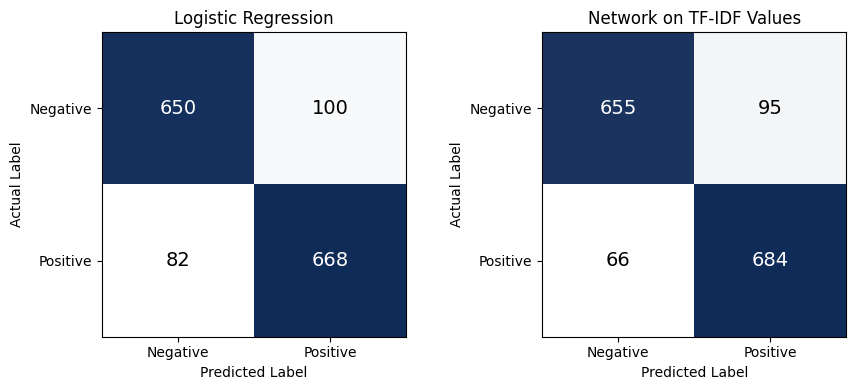

In [11]:
def plot_confusion_matrices(y_true, predictions):
    colors = LinearSegmentedColormap.from_list("navy", ["#FFFFFF", "#0F2B58"])
    fig, axes = plt.subplots(1, len(predictions), figsize=(4.5 * len(predictions), 4), squeeze=False)
    for ax, (name, predicted) in zip(axes[0], predictions.items()):
        matrix = confusion_matrix(y_true, predicted)
        ax.imshow(matrix, cmap=colors)
        for row in range(2):
            for column in range(2):
                color = "white" if matrix[row, column] > matrix.max() / 2 else "black"
                ax.text(column, row, matrix[row, column], ha="center", va="center", color=color, fontsize=14)
        ax.set_xticks([0, 1], ["Negative", "Positive"])
        ax.set_yticks([0, 1], ["Negative", "Positive"])
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")
        ax.set_title(name)
    plt.tight_layout()
    plt.show()

plot_confusion_matrices(y_test, predictions)

The network should make fewer errors than the baseline in both rows, most of all on positive reviews, with about 66 labeled negative against 82.

## 9. Saving and Reloading the Classifier

`save()` writes the network's layers and weights to a `.keras` file, and **joblib** saves the fitted vectorizer, which new reviews need. Files saved in Colab are deleted when the runtime ends, so download them from the Files panel to keep them.

Both files are reloaded, and the reloaded network is checked against the test predictions above:

In [12]:
network.save("tfidf_network.keras")
joblib.dump(tfidf, "tfidf_vectorizer.joblib")

loaded_network = keras.models.load_model("tfidf_network.keras")
loaded_tfidf = joblib.load("tfidf_vectorizer.joblib")
same = np.array_equal(predict_labels(loaded_network, tfidf_values(loaded_tfidf, texts_test)),
                      predictions["Network on TF-IDF Values"])
print("same test predictions after reloading:", same)

same test predictions after reloading: True


## 10. Predicting the Sentiment of New Reviews

`predict_reviews()` returns the predicted label of each review and its probability, the larger of the two softmax outputs:

- `texts`: a list of reviews.

- `model`: a trained network.

- `vectorizer`: the `TfidfVectorizer` the network was trained with.

The predictions for 5 sample reviews, written for this lab and not taken from the dataset, are displayed:

In [13]:
def predict_reviews(texts, model, vectorizer):
    probabilities = model.predict(tfidf_values(vectorizer, texts), verbose=0)
    return pd.DataFrame({
        "review": texts,
        "label": [LABELS[i] for i in probabilities.argmax(axis=1)],
        "probability": probabilities.max(axis=1).round(3),
    })

sample_reviews = [
    "One of the best films I have seen this year, with a wonderful cast and a moving story.",
    "A waste of two hours. The plot was boring and the acting was awful.",
    "The visuals were stunning, but the story was predictable and far too long.",
    "The film was good, not bad.",
    "The film was bad, not good.",
]
predict_reviews(sample_reviews, loaded_network, loaded_tfidf)

,review,label,probability
0,"One of the best films I have seen this year, with a wonderful cast and a moving story.",positive,0.995
1,A waste of two hours. The plot was boring and the acting was awful.,negative,0.997
2,"The visuals were stunning, but the story was predictable and far too long.",negative,0.854
3,"The film was good, not bad.",negative,0.977
4,"The film was bad, not good.",negative,0.977


The last 2 sample reviews contain the same words in a different order, so they have the same TF-IDF values and receive the same label and probability.

Replace the placeholder text of `custom_review` with any review, then run the cell to see its prediction:

In [14]:
custom_review = "Replace this text with a review."
predict_reviews([custom_review], loaded_network, loaded_tfidf)

,review,label,probability
0,Replace this text with a review.,negative,0.501
